### **TUGAS 3** *Machine Learning*
Nama : Panca Fadhliansyah
<p>
NIM : 048461548
<p>
Program Studi : S1 Statistika

In [1]:
# Customer Personality Analysis - Unsupervised Learning Tugas 3


import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## **Step 1**
Load DATASET

In [2]:
# Upload file
import os
try:
    from google.colab import files
    if not os.path.exists("/content/drive/MyDrive/Machine Learning/cpa.csv"):
        files.upload()
except ImportError:
    pass

# File cpa.csv menggunakan pemisah TAB (bukan koma), sehingga harus sep="\t"
df = pd.read_csv("/content/drive/MyDrive/Machine Learning/cpa.csv", sep="\t")
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


##**Step 2**
Eksplorasi Awal

In [3]:
#Struktur Data dan Tipe Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [4]:
# Jumlah missing value per kolom
missing = df.isnull().sum()
print(missing[missing > 0])
print("\nJumlah baris duplikat (semua kolom):", df.duplicated().sum())

Income    24
dtype: int64

Jumlah baris duplikat (semua kolom): 0


In [5]:
# Statistik deskriptif fitur numerik
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [6]:
# Distribusi fitur kategori
for col in ["Education", "Marital_Status"]:
    print(df[col].value_counts(), "\n")

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64 

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64 



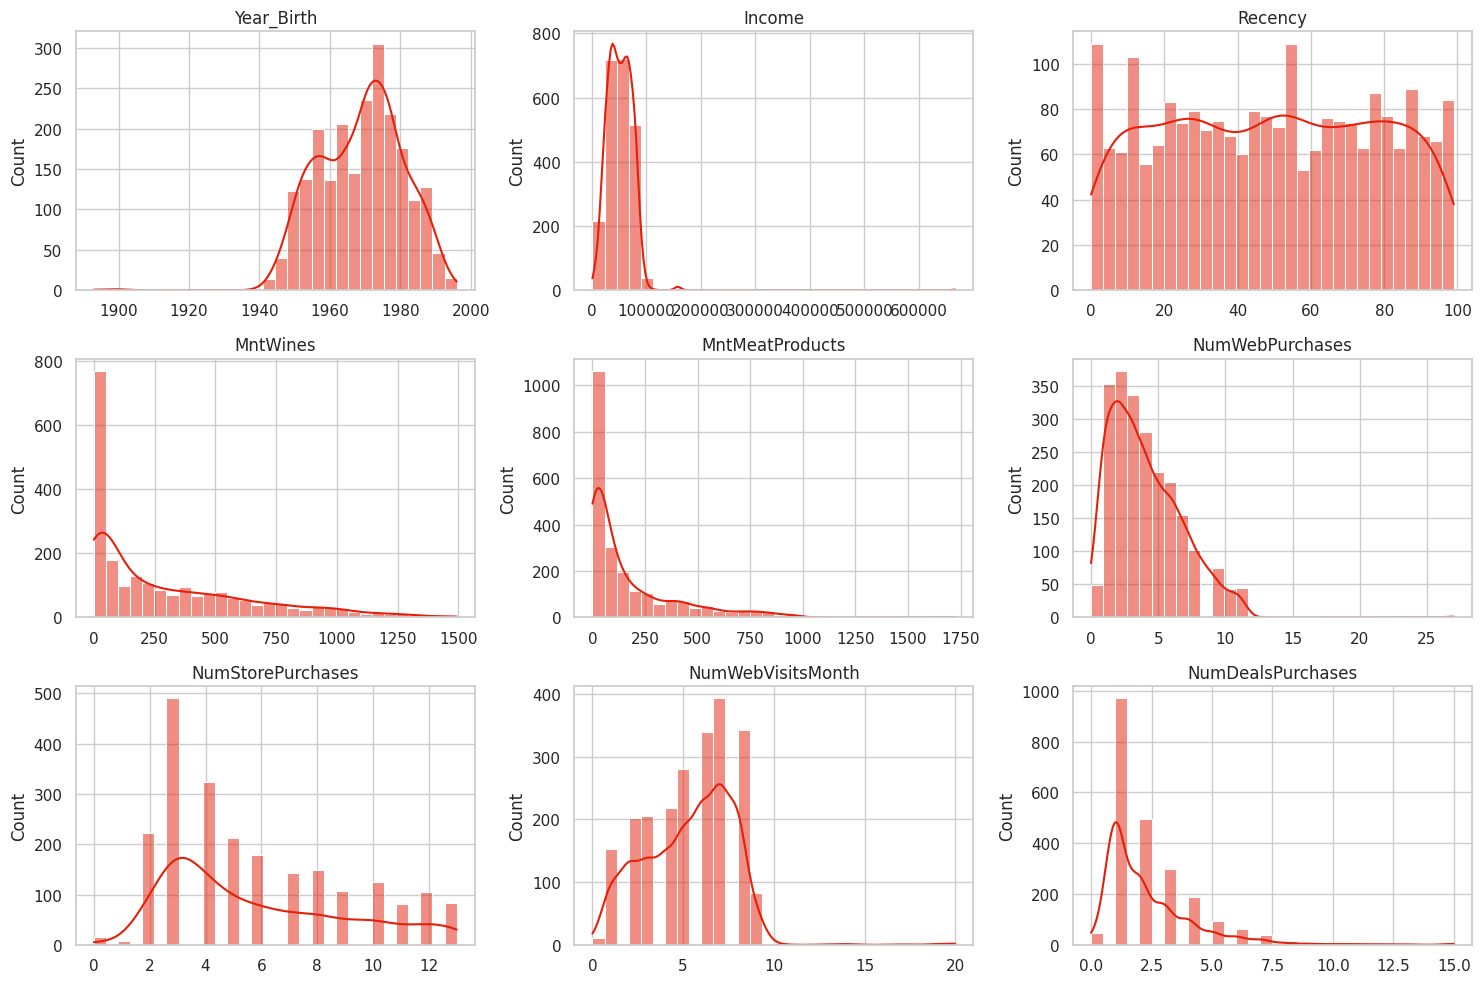

In [7]:
# Distribusi fitur utama
fitur_utama = ["Year_Birth", "Income", "Recency", "MntWines", "MntMeatProducts",
               "NumWebPurchases", "NumStorePurchases", "NumWebVisitsMonth", "NumDealsPurchases"]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.ravel(), fitur_utama):
    sns.histplot(df[col].dropna(), bins=30, kde=True, ax=ax, color="#E41F0A")
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Berikut yang ditemukan pada eksplorasi awal:**
- Data berisi 2.240 pelanggan dan 29 kolom, dengan pemisah TAB.
- Hanya kolom `Income` yang memiliki missing value (24 baris).
- Ada kolom yang tidak berguna untuk klastering: `ID` (identitas), `Z_CostContact` dan `Z_Revenue` (nilainya konstan).
- Terdapat outlier: `Income` maksimum 666.666 (jauh dari yang lain) dan `Year_Birth` 1893-1900 (usia tidak masuk akal).
- Fitur pengeluaran (`Mnt...`) dan `Income` miring ke kanan (right-skewed).
- Fitur kategori: `Education` dan `Marital_Status` (ada kategori aneh: `Alone`, `Absurd`, `YOLO`).

##**Step 3**
Identifikasi Kolom Numerik & Kategori

In [8]:
# 1) Feature engineering ringan dari kolom tanggal & tahun lahir
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
ref_date = df["Dt_Customer"].max()
df["Customer_Tenure"] = (ref_date - df["Dt_Customer"]).dt.days   # lama menjadi pelanggan (hari)
df["Age"] = ref_date.year - df["Year_Birth"]                     # usia pada tanggal referensi

# 2) Buang outlier yang tidak masuk akal (Income NaN tetap dipertahankan untuk diimputasi)
n_awal = len(df)
df = df[(df["Age"] <= 90) & ~(df["Income"] > 200000)].reset_index(drop=True)
print(f"Outlier dibuang: {n_awal - len(df)} baris -> sisa {len(df)} baris")

# 3) Rapikan kategori Marital_Status yang tidak jelas
df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": "Single", "YOLO": "Single"})

# 4) Buang kolom yang tidak informatif / sudah diwakili fitur baru
kolom_konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan:", kolom_konstan)
drop_cols = ["ID", "Year_Birth", "Dt_Customer"] + kolom_konstan
X = df.drop(columns=drop_cols)

# 5) Pisahkan kolom numerik & kategori
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("\nKolom numerik  (%d):" % len(num_cols), num_cols)
print("\nKolom kategori (%d):" % len(cat_cols), cat_cols)

Outlier dibuang: 4 baris -> sisa 2236 baris
Kolom konstan: ['Z_CostContact', 'Z_Revenue']

Kolom numerik  (24): ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Response', 'Customer_Tenure', 'Age']

Kolom kategori (2): ['Education', 'Marital_Status']


##**Step 4**
Pengisian missing value

In [9]:
print("Missing value sebelum pengisian:\n", X.isnull().sum()[X.isnull().sum() > 0], "\n")

# Numerik -> median (tahan terhadap outlier / skewed)
num_imputer = SimpleImputer(strategy="median")
X_num = pd.DataFrame(num_imputer.fit_transform(X[num_cols]), columns=num_cols, index=X.index)

# Kategori -> modus (nilai paling sering)
cat_imputer = SimpleImputer(strategy="most_frequent")
X_cat = pd.DataFrame(cat_imputer.fit_transform(X[cat_cols]), columns=cat_cols, index=X.index)

print("Missing value sesudah proses pengisian (numerik + kategori):",
      X_num.isnull().sum().sum() + X_cat.isnull().sum().sum())

Missing value sebelum pengisian:
 Income    24
dtype: int64 

Missing value sesudah proses pengisian (numerik + kategori): 0


Kolom `Income` (satu-satunya yang memiliki missing value) diisi dengan **median** karena distribusinya miring ke kanan, sehingga median lebih stabil daripada mean.

##**Step 5**
Encoding fitur kategorik

In [10]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_enc = pd.DataFrame(ohe.fit_transform(X_cat),
                     columns=ohe.get_feature_names_out(cat_cols),
                     index=X.index)
print("Jumlah fitur hasil one-hot:", X_enc.shape[1])
X_enc.head()

Jumlah fitur hasil one-hot: 10


,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [11]:
# Gabungkan data numerik dan hasil encoding
X_final = pd.concat([X_num, X_enc], axis=1)
print("Ukuran data akhir (sebelum scaling):", X_final.shape)
X_final.head()

Ukuran data akhir (sebelum scaling): (2236, 34)


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response,Customer_Tenure,Age,Education_2n Cycle,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow
0,58138.0,0.0,0.0,58.0,635.0,88.0,546.0,172.0,88.0,88.0,3.0,8.0,10.0,4.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,663.0,57.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,46344.0,1.0,1.0,38.0,11.0,1.0,6.0,2.0,1.0,6.0,2.0,1.0,1.0,2.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,113.0,60.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,71613.0,0.0,0.0,26.0,426.0,49.0,127.0,111.0,21.0,42.0,1.0,8.0,2.0,10.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,312.0,49.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,26646.0,1.0,0.0,26.0,11.0,4.0,20.0,10.0,3.0,5.0,2.0,2.0,0.0,4.0,6.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,139.0,30.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,58293.0,1.0,0.0,94.0,173.0,43.0,118.0,46.0,27.0,15.0,5.0,5.0,3.0,6.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,161.0,33.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


##**Step 6**
Scaling Data

In [12]:
# K-Means berbasis jarak Euclidean, sehingga semua fitur harus berada pada skala yang sama
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)

# Cek: rata-rata ~0 dan standar deviasi ~1
print("Rata-rata maks (abs):", np.abs(X_scaled.mean(axis=0)).max().round(6))
print("Std min / maks     :", X_scaled.std(axis=0).min().round(3), "/", X_scaled.std(axis=0).max().round(3))

Rata-rata maks (abs): 0.0
Std min / maks     : 1.0 / 1.0


##**Step 7**
Menentukan jumlah cluster optimal (Elbow & Silhouette)

 k  Inertia (WCSS)  Silhouette
 2      64303.0630      0.1770
 3      60542.9361      0.1083
 4      57953.7167      0.1086
 5      55911.5577      0.1143
 6      54152.9707      0.0746
 7      51846.8315      0.1293
 8      51513.6745      0.0852
 9      50485.6199      0.0842
10      47606.2328      0.0947


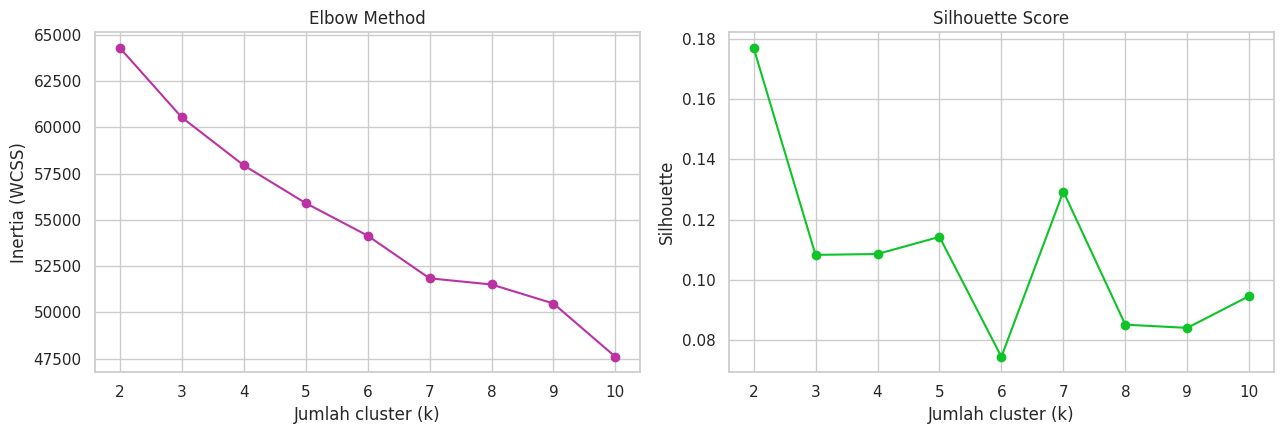

k dengan silhouette tertinggi: 2


In [13]:
K_range = range(2, 11)
inertias, sil_scores = [], []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

hasil_k = pd.DataFrame({"k": list(K_range), "Inertia (WCSS)": inertias, "Silhouette": sil_scores})
print(hasil_k.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(K_range, inertias, "o-", color="#BC32A2")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia (WCSS)")

axes[1].plot(K_range, sil_scores, "o-", color="#0EC428")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

print("k dengan silhouette tertinggi:", list(K_range)[int(np.argmax(sil_scores))])

**Interpretasi:**
- *Silhouette Score* tertinggi ada pada **k = 2** (0,177), jauh di atas k lainnya (k = 3 hanya 0,108).
- *Elbow* : inertia turun bertahap tanpa "siku" yang tegas, jadi tidak bertentangan dengan k = 2; elbow dipakai sebagai pendukung, keputusan utama dari Silhouette.
- Nilai *silhouette* yang rendah (< 0,25) menunjukkan klaster saling berdekatan/tumpang tindih. Ini wajar untuk data perilaku pelanggan yang sifatnya kontinu.

##**Step 8**
Pilih k optimal dan klasterisasi

In [14]:
# k dipilih berdasarkan Silhouette Score tertinggi (Elbow tidak menunjukkan siku yang tegas)
k_optimal = int(hasil_k.loc[hasil_k["Silhouette"].idxmax(), "k"])

kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("k optimal :", k_optimal)
print("Silhouette:", round(silhouette_score(X_scaled, df["Cluster"]), 4))
print("\nJumlah pelanggan per cluster:")
print(df["Cluster"].value_counts().sort_index())

k optimal : 2
Silhouette: 0.177

Jumlah pelanggan per cluster:
Cluster
0    1351
1     885
Name: count, dtype: int64


##**Step 9**
Visualisasi klaster dengan PCA 2D

Explained variance PC1 & PC2: [0.198 0.066] | total: 0.264


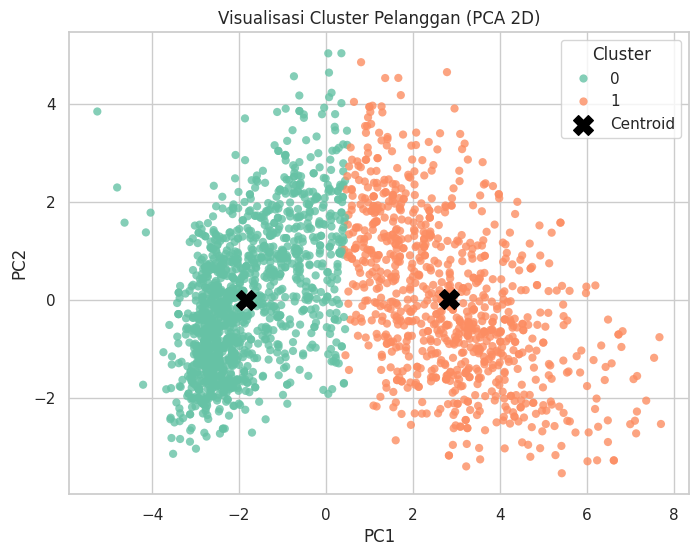

In [15]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance PC1 & PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["Cluster"], palette="Set2",
                s=35, alpha=0.8, edgecolor="none")
centers_pca = pca.transform(kmeans.cluster_centers_)
plt.scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=200, label="Centroid")
plt.title("Visualisasi Cluster Pelanggan (PCA 2D)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

##**Step 10**
Profiling cluster (rata-rata fitur per cluster)

In [16]:
# Fitur tambahan untuk memudahkan interpretasi (tidak dipakai saat klastering)
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Total_Spending"] = df[mnt_cols].sum(axis=1)
df["Total_Children"] = df["Kidhome"] + df["Teenhome"]
df["Total_Purchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
df["Total_Campaign_Accepted"] = df[["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3",
                                    "AcceptedCmp4", "AcceptedCmp5", "Response"]].sum(axis=1)

profil_cols = ["Age", "Income", "Total_Children", "Customer_Tenure", "Recency",
               "Total_Spending", "MntWines", "MntMeatProducts", "MntGoldProds",
               "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
               "NumStorePurchases", "NumWebVisitsMonth", "Total_Campaign_Accepted"]

profil = df.groupby("Cluster")[profil_cols].mean().round(2)
profil.insert(0, "Jumlah", df["Cluster"].value_counts().sort_index())
profil


,Jumlah,Age,Income,Total_Children,Customer_Tenure,Recency,Total_Spending,MntWines,MntMeatProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Total_Campaign_Accepted
Cluster,,,,,,,,,,,,,,,,
0,1351,43.96,39015.99,1.25,338.70,48.86,188.94,104.89,37.80,22.81,2.54,2.97,0.90,3.98,6.39,0.20
1,885,46.85,71660.83,0.49,376.78,49.51,1242.63,608.27,364.18,76.31,1.99,5.79,5.36,8.57,3.68,0.82


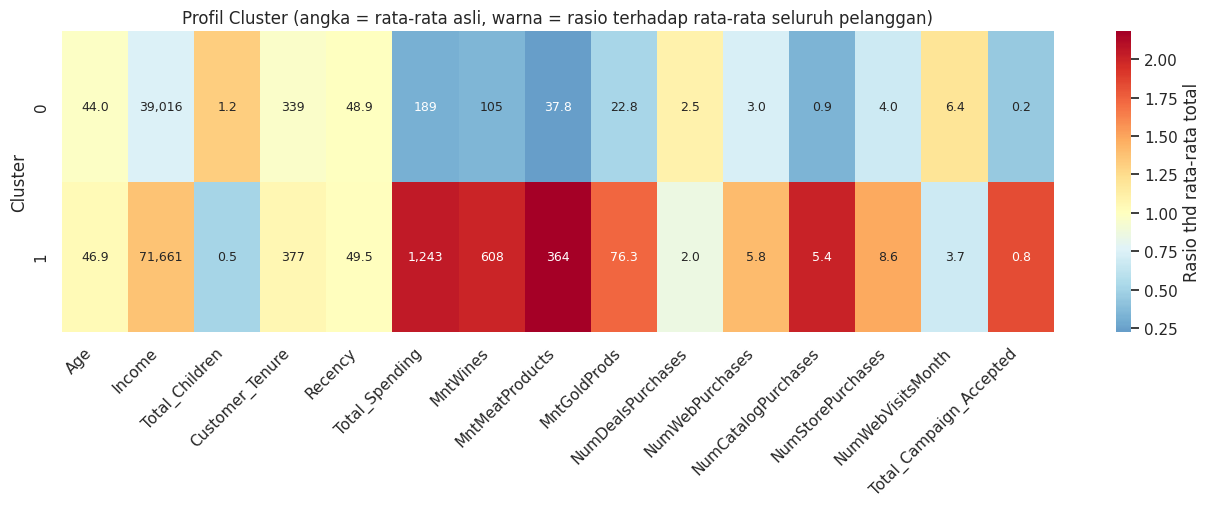

In [17]:
# Heatmap: rasio rata-rata tiap cluster terhadap rata-rata seluruh pelanggan (1.0 = rata-rata umum)
rasio = profil[profil_cols] / df[profil_cols].mean()
label = profil[profil_cols].map(lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.1f}")

plt.figure(figsize=(16, 2.5 + k_optimal * 0.7))
sns.heatmap(rasio, annot=label, fmt="", cmap="RdYlBu_r", center=1, annot_kws={"size": 9},
            cbar_kws={"label": "Rasio thd rata-rata total"})
plt.title("Profil Cluster (angka = rata-rata asli, warna = rasio terhadap rata-rata seluruh pelanggan)")
plt.ylabel("Cluster")
plt.xticks(rotation=45, ha="right")
plt.show()

In [18]:
# Distribusi pendidikan & status pernikahan per cluster (dalam %)
for col in ["Education", "Marital_Status"]:
    print((pd.crosstab(df["Cluster"], df[col], normalize="index") * 100).round(1), "\n")

# Proporsi pembelian per kategori produk per cluster
share = df.groupby("Cluster")[mnt_cols].sum()
share = (share.div(share.sum(axis=1), axis=0) * 100).round(1)
print("Proporsi pengeluaran per kategori produk (%):")
print(share)

Education  2n Cycle  Basic  Graduation  Master   PhD
Cluster                                             
0               9.4    3.9        48.4    17.6  20.7
1               8.4    0.1        53.3    14.9  23.3 

Marital_Status  Divorced  Married  Single  Together  Widow
Cluster                                                   
0                    9.6     39.7    21.8      26.1    2.7
1                   11.4     36.9    21.6      25.5    4.5 

Proporsi pengeluaran per kategori produk (%):
         MntWines  MntFruits  MntMeatProducts  MntFishProducts  \
Cluster                                                          
0            55.5        3.5             20.0              5.2   
1            49.0        4.5             29.3              6.4   

         MntSweetProducts  MntGoldProds  
Cluster                                  
0                     3.6          12.1  
1                     4.7           6.1  


**Profil klaster (k = 2):**

| | Cluster 0 - "Budget / Low Spender" | Cluster 1 - "Premium / High Spender" |
|---|---|---|
| Jumlah | 1.351 (60%) | 885 (40%) |
| Rata-rata Income | ± 39 ribu | ± 71,7 ribu |
| Jumlah anak | 1,25 | 0,49 |
| Total belanja | ± 189 | ± 1.243 (6,6x lipat) |
| Pembelian katalog | 0,9 | 5,4 |
| Pembelian toko | 4,0 | 8,6 |
| Kunjungan web/bulan | 6,4 | 3,7 |
| Kampanye diterima | 0,20 | 0,82 |

Hal-hal penting:
- Pembeda utama klaster adalah **Income, jumlah anak, dan volume belanja**.
- `Recency`, `Education`, dan `Marital_Status` hampir sama antar klaster, sehingga bukan pembeda yang kuat.
- Cluster 0 sering mengunjungi web tetapi jarang membeli, dan porsi belanja emas (`MntGoldProds`) lebih besar (12,1% vs 6,1%), menandakan sensitif harga.
- Cluster 1 berbelanja banyak lewat katalog dan toko, dengan porsi daging lebih besar (29,3% vs 20,0%), dan paling responsif terhadap kampanye.

## **Kesimpulan dan Hasil Analisis**

**Kesimpulan:**

1. *Preprocessing* : Data dibaca dengan pemisah TAB (2.240 baris, 29 kolom). Hanya `Income` yang memiliki missing value (24 baris), diimputasi dengan median. Empat baris outlier (usia > 90 tahun dan Income 666.666) dibuang, kolom konstan (`Z_CostContact`, `Z_Revenue`) dan `ID` dihapus. `Education` dan `Marital_Status` di-one-hot-encode, lalu seluruh fitur distandarisasi dengan `StandardScaler` (34 fitur, 2.236 pelanggan).
2. Jumlah klaster: Silhouette Score tertinggi pada **k = 2** (0,177), sedangkan Elbow tidak menunjukkan siku tegas. Maka K-Means dijalankan dengan k = 2. Silhouette yang rendah menandakan klaster tidak terpisah tegas (PCA 2 komponen hanya menjelaskan ± 26% varians).
3. Segmentasi (k = 2) :
   - Cluster 1 - Premium (40%) : income tinggi (± 71,7 ribu), sedikit anak, belanja besar (± 1.243), aktif di toko dan katalog, paling responsif terhadap kampanye.
   - Cluster 0 - Budget (60%): income lebih rendah (± 39 ribu), lebih banyak anak, belanja kecil (± 189), banyak browsing web tetapi jarang membeli.
4. Rekomendasi bisnis :
   - Premium: program loyalitas, penawaran eksklusif, dan promosi via katalog/toko, karena segmen ini paling bernilai dan paling responsif.
   - Budget: diskon, bundling, dan promo di web untuk mengubah kunjungan menjadi pembelian.
6. **Catatan.** `Recency`, pendidikan, dan status pernikahan tidak membedakan klaster secara berarti; perilaku pembelian dan pendapatan adalah pembeda utama.